# Subclustering and Annotation with Imputation

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import squidpy as sq
import scicm
import anndata
import seaborn as sns
import numpy as np
import scanpy as sc
import os
import pandas as pd
from Xenium_5K_IPF_constants import IMP_GENE_NAMES, SAMPLES_SYMBOLS, TITLE_ABBREVIATION, SUBTYPE_HATCHES, WORK_PATH

# Option
sc.settings.verbosity = 3
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

# Constant Declaration
sub_cluster={  # subtype: {top_gene_hvg, n_comp, n_neighbor, min_dist, resolution}
    "Epithelial": {"hvg": 2000, "n_comp": 15, "n_neighbor": 50, "min_dist": 0.3, "resolution": 0.6}, 
    "Fibroblast": {"hvg": 2000, "n_comp": 20, "n_neighbor": 100, "min_dist": 0.3, "resolution": 0.4},  
    "Macrophage": {"hvg": 1000, "n_comp": 5, "n_neighbor": 80, "min_dist": 0.5, "resolution": 0.3},  
}
GSE = ["135893", "136831"]
deg_num = 1000  

In [ ]:
# Select subtype for clustering

sub_type = "Epithelial"
# sub_type = "Fibroblast"
# sub_type = "Macrophage"

In [ ]:
# Data loading
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/1st_clustering.h5ad")

In [ ]:
adata.layers["norm_log"]=adata.X.copy()
adata.X = adata.raw.X.copy()

In [ ]:
imp_adata = adata[adata.obs["cell_type"]==sub_type].copy()

In [ ]:
# clustering
sub_cl = sub_cluster[sub_type]
sc.experimental.pp.highly_variable_genes(imp_adata, flavor="pearson_residuals", n_top_genes=sub_cl["hvg"], batch_key="sample")
imp_adata.X = imp_adata.layers["pearson"].copy()
sc.pp.pca(imp_adata, n_comps=sub_cl["n_comp"], mask_var="highly_variable")
sc.pp.neighbors(imp_adata, use_rep='X_pca', n_neighbors=sub_cl["n_neighbor"])
sc.tl.umap(imp_adata, min_dist=sub_cl["min_dist"])
sc.tl.leiden(imp_adata, resolution=sub_cl["resolution"], key_added='leiden', flavor="igraph", n_iterations=-1, directed=False)

In [ ]:
# UMAP of leiden clustering
fig, ax = plt.subplots(1,1, figsize=(5,5))
plt.subplots_adjust(left=0, right=1, bottom=0, top=1)
sc.pl.umap(imp_adata,color="leiden", legend_loc="on data", vmax=10, s=5, ax=ax, legend_fontoutline=3, legend_fontsize=30, show=False)
plt.title("")
plt.axis("off")

plt.savefig(f"{WORK_PATH}Figure/013_{sub_type}_umap_leiden.png", dpi=500, format="png", bbox_inches=None)
plt.show()

In [ ]:
# Loading imputation data

# stAI
imp_df_gse=[]
for p, gse in enumerate(GSE):
    imp_df = []
    for n, ss in enumerate(SAMPLES_SYMBOLS):
        imp_df.append(pd.read_csv(f"{WORK_PATH}Imputation/stAI/CSV/GSE{gse}/{sub_type}_imp_{ss}.csv", index_col=0))
        
        imp_df[n].index = [imp_df[n].index[m][:-1]+str(n) for m in range(len(imp_df[n]))]
    imp_df = pd.concat(imp_df)
    gse_dict={}
    for ge in IMP_GENE_NAMES[sub_type]:
        gse_dict[ge]=ge+"_stai_Ref."+str(p+1)
    imp_df = imp_df[IMP_GENE_NAMES[sub_type]]
    imp_df = imp_df.rename(columns=gse_dict)
    imp_df_gse.append(imp_df)
imp_df_m = imp_df_gse[0]
for g in range(1,len(GSE)):
    imp_df_m = pd.merge(left=imp_df_m, right=imp_df_gse[g], left_index=True, right_index=True) 
imp_adata.obs = pd.merge(left=imp_adata.obs, right=imp_df_m, left_index=True, right_index=True)

# TANGRAM
tang_adata_0 = sc.read_h5ad(f"{WORK_PATH}Imputation/TANGRAM/GSE{GSE[0]}/Tangram_{sub_type}.h5ad")
tang_adata_1 = sc.read_h5ad(f"{WORK_PATH}Imputation/TANGRAM/GSE{GSE[1]}/Tangram_{sub_type}.h5ad")


for gene in IMP_GENE_NAMES[sub_type]:
    imp_adata.obs[gene+"_tang_Ref.1"] = tang_adata_0[:, gene.lower()].X.toarray().flatten()
    imp_adata.obs[gene+"_tang_Ref.2"] = tang_adata_1[:, gene.lower()].X.toarray().flatten()

In [ ]:
# imputated genes
if sub_type == "Epithelial":
    gene_sets_imp = {
        "SFTPC": "AT2",
        "CAV1": "AT1",
        "KRT5": "Basal",
        "KRT17": "Basal, KRT5-/KRT17+",
        "KRT8": "KRT5-/KRT17+",
        "SCGB3A2": "Secretory",
        "SCGB1A1": "Secretory",
        "CAPS": "Ciliated"
    }
    vmax_r = 0.8
    
elif sub_type == "Fibroblast":
    gene_sets_imp = {
        "ACTA2": "Myofibroblast", 
        "COL1A1": "Myofibroblast", 
        "ITGA8": "Lipofibroblast",
    }
    vmax_r = 0.8
    
elif sub_type == "Macrophage":
    gene_sets_imp = {
        "SPP1": "SPP1+ MΦ", 
        "PLA2G7": "SPP1+ MΦ", 
        "CHI3L1": "SPP1+ MΦ", 
        "FABP4": "Alveolar MΦ"
    }
    vmax_r = 0.8

In [ ]:
# UMAP of imputated gene expression
cmaps = ["scicm.Cyan", "scicm.Green", "scicm.Red", "scicm.Purple"]
labels = [f"stAI (GSE{GSE[0]})", f"stAI (GSE{GSE[1]})", f"TANGRAM (GSE{GSE[0]})", f"TANGRAM (GSE{GSE[1]})"]
gene_list = [f"{g}_{f}" for f in ["stai_Ref.1", "stai_Ref.2", "tang_Ref.1", "tang_Ref.2"]  for g in IMP_GENE_NAMES[sub_type]]
num_g = len(gene_sets_imp)

fig, axes = plt.subplots(4, num_g, figsize=(((num_g+3)*1.2+(num_g-1)*0.4),(4*1.2 + 3*0.08)/0.88))
fig.subplots_adjust(left=0, right=((num_g*1.2+(num_g-1)*0.4))/(((num_g+3)*1.2+(num_g-1)*0.4)), top=0.9, bottom=0.02, wspace=0.4, hspace=0.08)

for i in range(axes.size):
    row, col = i // num_g,  i % num_g, 
    cmap = plt.get_cmap(cmaps[row])
    if row  > 1:
        vmax = imp_adata.obs[gene_list[i]].max() * vmax_r
    else:
        vmax = imp_adata.obs[gene_list[i]].max()
    sc.pl.umap(
        imp_adata,
        color=gene_list[i],
        s=2,
        ax=axes[row][col],
        show=False,
        colorbar_loc=None,
        cmap=cmap,
        vmax = vmax
    )
    axes[row][col].axis("off")
    axes[row][col].set_title("")
    if row == 0:
        axes[row][col].text(0.5, 1.11, IMP_GENE_NAMES[sub_type][col], transform=axes[row][col].transAxes, ha="center", va="bottom", fontsize=18, fontdict={"style":"italic"})
        if gene_sets_imp[IMP_GENE_NAMES[sub_type][col]] in TITLE_ABBREVIATION:
            tx = TITLE_ABBREVIATION[gene_sets_imp[IMP_GENE_NAMES[sub_type][col]]]
        else:
            tx = gene_sets_imp[IMP_GENE_NAMES[sub_type][col]]
        axes[row][col].text(0.5, 1.1, tx, transform=axes[row][col].transAxes, ha="center", va="top", fontsize=13)

    norm = matplotlib.colors.Normalize(vmin=0, vmax=vmax)
    sm = plt.cm.ScalarMappable(cmap=cmaps[row], norm=norm)
    cbar_ax = fig.add_axes([
        axes[row][col].get_position().width*0.02+axes[row][col].get_position().x1, 
        axes[row][col].get_position().height*0.1+axes[row][col].get_position().y0, 
        axes[row][col].get_position().width*0.08, 
        axes[row][col].get_position().height/2
    ])
    fig.colorbar(sm, cax=cbar_ax)

legend_ax = fig.add_subplot([(num_g+0.4)/(num_g+2.5), 0.6, 2.1/(num_g+2.5), 0.3])
legend_ax.set_xlim(0, 1.5)
legend_ax.set_ylim(0, len(cmaps))
legend_ax.axis("off")

for i in range(len(cmaps)):
    grad = np.linspace(0, 1, 256).reshape(1, -1)
    cmap = plt.get_cmap(cmaps[i])
    extent = [0, 0.3, 3-i, 3.6-i]
    legend_ax.imshow(grad, aspect="auto", cmap=cmap, extent=extent)
    legend_ax.text(0.33, 3.3-i, labels[i], va='center', fontsize=17)
    
plt.savefig(f"{WORK_PATH}Figure/013_{sub_type}_umap_imputated_genes.png", dpi=500, format="png", bbox_inches=None)
plt.show()

In [ ]:
# marker genes
cmap = matplotlib.colormaps.get_cmap("inferno").copy()
cmap.set_under("lightgrey")               # value 0 color
if sub_type == "Epithelial":
    row, col=4, 4
    gene_sets = {
            "LAMP3": ("AT2", 20),
            "ABCA3": ("AT2", 20),
            "AGER": ("AT1", 14),
            "RTKN2": ("AT1", 14),
            "ITGB6": ("KRT5-/KRT17+", 30),
            "CDKN2B": ("KRT5-/KRT17+", 14),
            "ANXA8": ("Basal", 14),
            "TP63": ("Basal", 6),
            "MUC5B": ("Goblet", 25),
            "FCGBP": ("Goblet", 8),        
            "FOXJ1": ("Ciliated", 18),
            "TPPP3": ("Ciliated", 20)
        }

elif sub_type == "Fibroblast":
    row, col=4, 3
    gene_sets = {
            "POSTN": ("Myofibroblast", 60),
            "CTHRC1": ("Myofibroblast", 15),
            "COMP": ("COMP+ fib.", 17),
            "GREM1": ("GREM1+ fib.", 15),
            "TCF21": ("Lipofibroblast", 11),
            "AOC3": ("Lipofibroblast", 14),
            "PI16": ("Adventitial fib.", 14),
            "CD34": ("Adventitial fib.", 6),
        }

elif sub_type == "Macrophage":
    row, col=4, 2
    gene_sets = {
            "F13A1": ("Interstitial MΦ", 17),
            "MMP9": ("SPP1+ MΦ", 13),
            "CXCL9": ("CXCL9+ MΦ", 12),    
            "ALDH2": ("Alveolar MΦ", 15),
        }

In [ ]:
# Subtype annotation
if sub_type == "Epithelial":
    sub_celltype = {
        "AT2": [4,6],
        "AT1": [10],
        "KRT5-/KRT17+": [5],
        "Basal": [2,7],
        "Secretory": [1,3],
        "Goblet": [0,9],
        "Ciliated": [8,11],
    }
    sub_legend_mdf = {
        "AT2": (-1.2, 1.6),
        "AT1": (0, 1),
        "KRT5-/KRT17+": (1, 0),
    }

elif sub_type == "Fibroblast":
    sub_celltype = {
        "Myofibroblast": [5], 
        "COMP+ fibroblast": [7],
        "GREM1+ fibroblast": [2],
        "Adventitial fibroblast": [4,8],
        "Lipofibroblast": [0,1,3,6]
    }

    sub_legend_mdf = {
    }

elif sub_type == "Macrophage":
    sub_celltype = {
        "Interstitial macrophage": [0, 4],
        "SPP1+ macrophage": [1],
        "CXCL9+ macrophage": [2],
        "Alveolar macrophage": [3]
    }
    sub_legend_mdf = {
    }

In [ ]:
subtype_lei2key = {}
for cl, le in sub_celltype.items():
    for l in le:
        subtype_lei2key[str(l)] = cl
subtype_lei2key_sort = {}
for l in range(len(imp_adata.obs["leiden"].unique())):
    subtype_lei2key_sort[str(l)] = subtype_lei2key[str(l)]
imp_adata.obs['subtype'] = imp_adata.obs['leiden'].map(subtype_lei2key_sort).astype('category')
imp_adata.obs['subtype'] = pd.Categorical(values=imp_adata.obs['subtype'], categories=list(sub_celltype), ordered=True)

In [ ]:
# UMAP of marker gene expression

umap_box = 1.7
umap_spa = [0.25, 0.4]
fig, axes = plt.subplots(row, col, figsize=((col*umap_box + (col-1)*umap_spa[0])/(col/(col+0.2)),(row*umap_box + (row-1)*umap_spa[1])/0.93))
fig.subplots_adjust(left=0, right=col/(col+0.2), top=0.94, bottom=0.01, wspace=umap_spa[0], hspace=umap_spa[1])
axes = axes.flatten()
for n in [0,1, col, col+1]:
    axes[n].axis("off")
axes_c = np.concatenate([axes[2:col],axes[col+2:]])

for ax, (key, val) in zip(axes_c, gene_sets.items()):
    sc.pl.umap(
        imp_adata,
        color=key,
        s=3,
        show=False,
        colorbar_loc=None,
        cmap=cmap,
        vmin=1, 
        vmax = val[1],
        ax = ax,
    )
    ax.axis("off")
    ax.set_title("")
    ax.text(0.5, 1.11, key, transform=ax.transAxes, ha="center", va="bottom", fontsize=18, fontdict={"style":"italic"})
    ax.text(0.5, 1.1, val[0], transform=ax.transAxes, ha="center", va="top", fontsize=15)

    norm = matplotlib.colors.Normalize(vmin=1, vmax=val[1])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    cbar_ax = fig.add_axes([
        ax.get_position().width*0.02+ax.get_position().x1, 
        ax.get_position().height*0.1+ax.get_position().y0, 
        ax.get_position().width*0.05, 
        ax.get_position().height/2
    ])
    fig.colorbar(sm, cax=cbar_ax)
    cbar_ax.tick_params("y", size=2)

l_ax_w = (1+(col/(col+0.2)))/col 
fig.get_figheight()
fig.get_figwidth()
l_ax = fig.add_axes([0, (row-2)/row, l_ax_w, l_ax_w*fig.get_figwidth()/fig.get_figheight()])

sc.pl.umap(imp_adata, color="subtype", legend_loc="on data", s=3, ax=l_ax, legend_fontoutline=2, legend_fontsize=16, show=False)
l_ax.set_title(sub_type, fontsize=20)
l_ax.axis("off")


for txt in l_ax.texts:
    lb = txt.get_text()
    if lb in list(sub_legend_mdf):
        x,y = sub_legend_mdf[lb]
        txt.set_position((txt.get_position()[0]+x, txt.get_position()[1]+y))
    txt.set_text(lb.replace(" ", "\n"))
    
plt.savefig(f"{WORK_PATH}Figure/013_{sub_type}_umap_cellmarker_genes.png", dpi=500, format="png", bbox_inches=None)
plt.show()

In [ ]:
# DGE analysis
imp_adata.X=imp_adata.raw.X.copy()
sc.pp.normalize_total(imp_adata, target_sum=1e4)
sc.pp.log1p(imp_adata)
sc.tl.dendrogram(imp_adata, groupby="subtype", use_raw=True)
sc.tl.rank_genes_groups(imp_adata, groupby="subtype", use_raw=False, n_genes=deg_num, method='wilcoxon')

rg = imp_adata.uns["rank_genes_groups"]
groups = list(rg["names"].dtype.names)  
gene_to_col = {g: i for i, g in enumerate(imp_adata.var_names)}

frac_by_group = {}
obs_grp = imp_adata.obs["subtype"].values

for g in groups:
    mask = (obs_grp == g)
    n_cells = int(mask.sum())
    if n_cells == 0:
        frac_by_group[g] = np.zeros(imp_adata.n_vars, dtype=float)
        continue

    subX = imp_adata.X[mask, :].tocsr()
    hits = subX.copy()
    hits.data = (hits.data > 0).astype(np.int8)
    frac = np.asarray(hits.sum(axis=0)).ravel() / n_cells

    frac_by_group[g] = frac

leiden_deg_df = pd.DataFrame(columns=[i for i in range(deg_num*len(groups))], index=["subtype", "genes", "fractions", 'scores', 'pvals', 'pvals_adj', 'logfoldchanges'])

for n, g in enumerate(groups):
    for i in range(deg_num):
        leiden_deg_df.loc["subtype", i+deg_num*n]=g
        leiden_deg_df.loc["genes", i+deg_num*n]=rg["names"][i][n]
        leiden_deg_df.loc["fractions", i+deg_num*n]=frac_by_group[g][gene_to_col[rg["names"][i][n]]]
        for t in ['scores', 'pvals', 'pvals_adj', 'logfoldchanges']:
            leiden_deg_df.loc[t, i+deg_num*n]=rg[t][i][n].astype(np.float64)
leiden_deg_df.T.to_csv(f"{WORK_PATH}CSV/013_degs_{sub_type}.csv", index=False)

In [ ]:
# Stacked bar of subtype proportion
ct_counts = pd.crosstab(imp_adata.obs['sample'], imp_adata.obs['subtype'])
ct_props = ct_counts.div(ct_counts.sum(axis=1), axis=0)

cell_type_order = ct_counts.columns.tolist()

ct_props = ct_props[cell_type_order[::-1]] 

colors = imp_adata.uns["subtype_colors"]
colors_for_plot = colors[::-1]

ax = ct_props.plot(kind='bar', stacked=True, figsize=(7, 4), color=colors_for_plot)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], title='', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=15, edgecolor="none")

plt.ylabel(f'Subtype proportion of {sub_type}', fontsize=15)
plt.xlabel('')
plt.xticks(size=15, rotation=45, rotation_mode='anchor', ha="right", va="top")
plt.tick_params("y", labelsize=13)
plt.subplots_adjust(left=0.1, right=0.45, bottom=0.18, top=0.98)

plt.savefig(f"{WORK_PATH}Figure/013_{sub_type}_stackedbar.png", dpi=500, format="png", bbox_inches=None)
plt.show()

In [ ]:
ct_props = ct_props[cell_type_order[:]]

df_source = pd.DataFrame(index=ct_props.index, columns=ct_props.columns)

for col in ct_props.columns:
    df_source[col] = [
        f"{p * 100:.2f}% ({n:,})"
        for p, n in zip(ct_props[col], ct_counts.loc[ct_props.index, col])
    ]

df_source.index.name = "Sample"
df_source.to_csv(f"{WORK_PATH}CSV/013_{sub_type}_stackedbar_source_data.csv", index=True)

df_source

In [ ]:
# Saving subtype annotation of each cell
tc_csv = pd.DataFrame({"cell_id":imp_adata.obs_names.to_list(),"subtype":imp_adata.obs["subtype"].to_list()})
tc_csv.to_csv(f"{WORK_PATH}CSV/013_subtype_{sub_type}.csv", index=False, encoding="utf-8-sig")

In [ ]:
imp_adata.write(f"{WORK_PATH}AnnData/{sub_type}.h5ad")

In [ ]:
genes = {
    "Epithelial": ["SFTPC", "CAV1", "KRT5", "KRT17", "KRT8", "SCGB3A2", "SCGB1A1", "CAPS"],
    "Fibroblast": ["ACTA2", "COL1A1", "ITGA8"],
    "Macrophage": ["SPP1", "PLA2G7", "CHI3L1", "FABP4"]
}

conditions = {
    "stAI (Ref.1)": ("stai", "Ref.1"),
    "stAI (Ref.2)": ("stai", "Ref.2"),
    "Tangram (Ref.1)": ("tang", "Ref.1"),
    "Tangram (Ref.2)": ("tang", "Ref.2"),
}

cmap={
    "Epithelial": "Reds",
    "Fibroblast": "Blues",
    "Macrophage": "Oranges"
}

obs = imp_adata.obs

column_map = {}

for condition, (method, reference) in conditions.items():
    for gene in genes[sub_type]:
        expected = f"{gene}_{method}_{reference}"
        column_map[(condition, gene)] = obs[expected]


In [ ]:
rows = []
subtype_order = list(sub_celltype)

for condition in conditions:

    for gene in genes[sub_type]:

        col = column_map[(condition, gene)]

        temp = pd.DataFrame({
            "subtype": obs["subtype"].astype(str),
            "expression": pd.to_numeric(
                col, errors="coerce"
            )
        })

        temp = temp[temp["subtype"].isin(subtype_order)]

        stats = (
            temp.groupby("subtype")["expression"]
            .agg(["mean", "count"])
            .reindex(subtype_order)
        )

        for subtype in subtype_order:

            rows.append({
                "condition": condition,
                "gene": gene,
                "subtype": subtype,
                "mean_expression": stats.loc[subtype, "mean"],
                "n_cells": stats.loc[subtype, "count"],
            })

imp_df = pd.DataFrame(rows)

# min-max scaling
grouped = imp_df.groupby(["condition", "gene"])["mean_expression"]

gene_min = grouped.transform("min")
gene_max = grouped.transform("max")

imp_df["scaled_expression"] = (
    (imp_df["mean_expression"] - gene_min) /
    (gene_max - gene_min).replace(0, np.nan)
)

In [ ]:
left_bl = 8
right_bl = 5
top_bl = 1.5
bottom_bl= 2.2
ws = 1
wd = left_bl + right_bl + len(genes[sub_type])*4 + ws*3
ht = top_bl + bottom_bl + len(subtype_order)
w_rt = [len(genes[sub_type]), ws]*3 +[len(genes[sub_type])]
fig, axes = plt.subplots(1, 7, figsize=(wd*0.25, ht*0.28), sharex=True, sharey=True, width_ratios=w_rt)

fig.subplots_adjust(left=left_bl/wd, right=1-right_bl/wd, bottom=bottom_bl/ht, top=1-top_bl/ht, wspace=0)

for ax in [axes[1], axes[3], axes[5]]:
    ax.axis("off")

for i, (ax, condition) in enumerate(zip([axes[2*n] for n in range(4)], conditions)):

    sub = imp_df[imp_df["condition"] == condition]

    mat = sub.pivot(
        index="subtype",
        columns="gene",
        values="scaled_expression"
    ).reindex(
        index=subtype_order,
        columns=genes[sub_type]
    )

    sns.heatmap(
        mat,
        cmap=cmap[sub_type],
        vmin=0,
        vmax=1,
        linewidths=0.3,
        linecolor="white",
        cbar=False,
        ax=ax
    )

    ax.set_title(condition.replace(" ", "\n"), fontsize=11, pad=8)
    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.tick_params(axis="y", labelsize=11, rotation=0)

    if i > 0:
        ax.tick_params(axis="y", labelleft=False)

for ax in axes:
    ax.set_xticklabels(
        genes[sub_type],
        rotation=45,
        ha="right",
        va="top",
        rotation_mode="anchor",
        fontsize=10
    )


cbar_ax = fig.add_axes([1-(right_bl-ws)/wd, 0.30, 0.5*ws/wd, 0.45])

sm = plt.cm.ScalarMappable(cmap=cmap[sub_type],　norm=plt.Normalize(0, 1))
sm.set_array([])

cbar = fig.colorbar(sm, cax=cbar_ax)

cbar.set_label("Relative mean\nimputed expression", fontsize=10)
cbar.ax.tick_params(labelsize=9)

fig.savefig(
    f"{WORK_PATH}Figure/013_{sub_type}_imputation_heatmap.png",
    dpi=500, bbox_inches="tight"
)


In [ ]:
# Heatmap source data
source_df = imp_df[
    [
        "condition",
        "subtype",
        "gene",
        "mean_expression",
        "scaled_expression",
        "n_cells",
    ]
].copy()

source_df["condition"] = pd.Categorical(
    source_df["condition"],
    categories=list(conditions.keys()),
    ordered=True
)

source_df["subtype"] = pd.Categorical(
    source_df["subtype"],
    categories=subtype_order,
    ordered=True
)

source_df["gene"] = pd.Categorical(
    source_df["gene"],
    categories=genes[sub_type],
    ordered=True
)

source_df = source_df.sort_values(["condition", "subtype", "gene"])

source_df.to_csv(
    f"{WORK_PATH}CSV/013_{sub_type}_imputation_heatmap_source_data.csv",
    index=False
)


# Subclustering and Annotation without Imputation

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import anndata
import numpy as np
import scanpy as sc
import os
import pandas as pd
from Xenium_5K_IPF_constants import WORK_PATH

# Option
sc.settings.verbosity = 3
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

# Constant Declaration
sub_cluster={
    "Endothelial": {"hvg": 2000, "n_comp": 7, "n_neighbor": 40, "min_dist": 0.3, "resolution": 0.3},  #0
    "SMC/Pericyte": {"hvg": 500, "n_comp": 5, "n_neighbor": 40, "min_dist": 0.5, "resolution": 0.2}  #1
}
deg_num = 1000

In [ ]:
# Select subtype for clustering

sub_type = "Endothelial"
# sub_type = "SMC/Pericyte"


In [ ]:
# Data loading
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/1st_clustering.h5ad")

In [ ]:
adata.layers["norm_log"]=adata.X.copy()
adata.X = adata.raw.X.copy()

In [ ]:
sub_adata = adata[adata.obs["cell_type"]==sub_type].copy()

In [ ]:
# clustering
sub_cl = sub_cluster[sub_type]
sc.experimental.pp.highly_variable_genes(sub_adata, flavor="pearson_residuals", n_top_genes=sub_cl["hvg"], batch_key="sample")
sub_adata.X = sub_adata.layers["pearson"].copy()
sc.pp.pca(sub_adata, n_comps=sub_cl["n_comp"], mask_var="highly_variable")
sc.pp.neighbors(sub_adata, use_rep='X_pca', n_neighbors=sub_cl["n_neighbor"])
sc.tl.umap(sub_adata, min_dist=sub_cl["min_dist"])
sc.tl.leiden(sub_adata, resolution=sub_cl["resolution"], key_added='leiden', flavor="igraph", n_iterations=-1, directed=False)

In [ ]:
# UMAP of leiden clustering
fig, ax = plt.subplots(1,1, figsize=(5,5))
plt.subplots_adjust(left=0, right=1, bottom=0, top=1)
sc.pl.umap(sub_adata, color="leiden", legend_loc="on data", s=3, ax=ax, legend_fontoutline=3, legend_fontsize=30, show=False)
plt.title("")
plt.axis("off")

plt.savefig(f"{WORK_PATH}Figure/013_{sub_type.replace("/", "_")}_umap_leiden.png", dpi=500, format="png", bbox_inches=None)
plt.show()

In [ ]:
# marker genes
cmap = matplotlib.colormaps.get_cmap("inferno").copy()
cmap.set_under("lightgrey")               # value 0 color
if sub_type == "Endothelial":
    row, col=3, 4
    gene_sets = {
        "PROX1": ("Lympathic", 6),
        "GJA5": ("Arteriole", 9),
        "VEGFC": ("Arteriole", 8),
        "HPGD": ("Aerocyte", 14),
        "TBX2": ("Aerocyte", 6),
        "SLC6A4": ("General capillary", 10),
        "TMEM100": ("General capillary", 10),
        "PLVAP": ("Venule", 12)
    }

elif sub_type == "SMC/Pericyte":
    row, col=3, 3
    gene_sets = {
        "PDGFRB": ("Pericyte, Alveolar Pericyte", 12),
        "STEAP4": ("Pericyte", 8),
        "KCNK3": ("Alveolar Pericyte", 8),
        "MYLK": ("Smooth muscle cell", 12),
        "CSRP1": ("Smooth muscle cell", 8),
    }


In [ ]:
# Subtype annotation
if sub_type == "Endothelial":
    sub_celltype = {
        "Lymphatic": [0], 
        "Arteriole": [5],
        "Aerocyte": [7],
        "General capillary": [2],
        "Venule": [1,3,4,6]
    }
    

elif sub_type == "SMC/Pericyte":
    sub_celltype = {
        "Smooth muscle cell": [2,3,5],
        "Pericyte": [1,4],
        "Alveolar Pericyte": [0]
    }


subtype_lei2key = {}
for cl, le in sub_celltype.items():
    for l in le:
        subtype_lei2key[str(l)] = cl
subtype_lei2key_sort = {}
for l in range(len(sub_adata.obs["leiden"].unique())):
    subtype_lei2key_sort[str(l)] = subtype_lei2key[str(l)]
sub_adata.obs['subtype'] = sub_adata.obs['leiden'].map(subtype_lei2key_sort).astype('category')
sub_adata.obs['subtype'] = pd.Categorical(values=sub_adata.obs['subtype'], categories=list(sub_celltype), ordered=True)

In [ ]:
# UMAP of marker gene expression

umap_box = 1.7
umap_spa = [0.25, 0.4]
fig, axes = plt.subplots(row, col, figsize=((col*umap_box + (col-1)*umap_spa[0])/(col/(col+0.25)),(row*umap_box + (row-1)*umap_spa[1])/0.91))
fig.subplots_adjust(left=0.005, right=col/(col+0.25), top=0.92, bottom=0.01, wspace=umap_spa[0], hspace=umap_spa[1])
axes = axes.flatten()
for n in [0,1, col, col+1]:
    axes[n].axis("off")
axes_c = np.concatenate([axes[2:col],axes[col+2:]])

for ax, (key, val) in zip(axes_c, gene_sets.items()):
    sc.pl.umap(
        sub_adata,
        color=key,
        s=3,
        show=False,
        colorbar_loc=None,
        cmap=cmap,
        vmin=1, 
        vmax = val[1],
        ax = ax,
    )
    ax.axis("off")
    ax.set_title("")
    ax.text(0.5, 1.11, key, transform=ax.transAxes, ha="center", va="bottom", fontsize=20, fontdict={"style":"italic"})
    ax.text(0.5, 1.1, val[0], transform=ax.transAxes, ha="center", va="top", fontsize=15)

    norm = matplotlib.colors.Normalize(vmin=1, vmax=val[1])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    cbar_ax = fig.add_axes([
        ax.get_position().width*0.02+ax.get_position().x1, 
        ax.get_position().height*0.1+ax.get_position().y0, 
        ax.get_position().width*0.05, 
        ax.get_position().height/2
    ])
    fig.colorbar(sm, cax=cbar_ax)
    cbar_ax.tick_params("y", size=2)

l_ax_w = (1+(col/(col+0.2)))/col 
fig.get_figheight()
fig.get_figwidth()
l_ax = fig.add_axes([0, (row-2)/row, l_ax_w, l_ax_w*fig.get_figwidth()/fig.get_figheight()])

sc.pl.umap(sub_adata, color="subtype", legend_loc="on data", s=3, ax=l_ax, legend_fontoutline=2, legend_fontsize=16, show=False)
l_ax.set_title(sub_type, fontsize=20)
l_ax.axis("off")

plt.savefig(f"{WORK_PATH}Figure/013_{sub_type.replace("/", "_")}_umap_cellmarker_genes.png", dpi=500, format="png", bbox_inches=None)

In [ ]:
# UMAP of marker gene expression

umap_box = 1.7
umap_spa = [0.25, 0.4]
fig, axes = plt.subplots(row, col, figsize=((col*umap_box + (col-1)*umap_spa[0])/(col/(col+0.2)),(row*umap_box + (row-1)*umap_spa[1])/0.93))
fig.subplots_adjust(left=0, right=col/(col+0.2), top=0.94, bottom=0.01, wspace=umap_spa[0], hspace=umap_spa[1])
axes = axes.flatten()
for n in [0,1, col, col+1]:
    axes[n].axis("off")
axes_c = np.concatenate([axes[2:col],axes[col+2:]])

for ax, (key, val) in zip(axes_c, gene_sets.items()):
    sc.pl.umap(
        imp_adata,
        color=key,
        s=3,
        show=False,
        colorbar_loc=None,
        cmap=cmap,
        vmin=1, 
        vmax = val[1],
        ax = ax,
    )
    ax.axis("off")
    ax.set_title("")
    ax.text(0.5, 1.11, key, transform=ax.transAxes, ha="center", va="bottom", fontsize=18, fontdict={"style":"italic"})
    ax.text(0.5, 1.1, val[0], transform=ax.transAxes, ha="center", va="top", fontsize=15)

    norm = matplotlib.colors.Normalize(vmin=1, vmax=val[1])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    cbar_ax = fig.add_axes([
        ax.get_position().width*0.02+ax.get_position().x1, 
        ax.get_position().height*0.1+ax.get_position().y0, 
        ax.get_position().width*0.05, 
        ax.get_position().height/2
    ])
    fig.colorbar(sm, cax=cbar_ax)
    cbar_ax.tick_params("y", size=2)

l_ax_w = (1+(col/(col+0.2)))/col 
fig.get_figheight()
fig.get_figwidth()
l_ax = fig.add_axes([0, (row-2)/row, l_ax_w, l_ax_w*fig.get_figwidth()/fig.get_figheight()])


In [ ]:
# DGE analysis
sub_adata.X=sub_adata.raw.X.copy()
sc.pp.normalize_total(sub_adata, target_sum=1e4)
sc.pp.log1p(sub_adata)
sc.tl.dendrogram(sub_adata, groupby="subtype")
sc.tl.rank_genes_groups(sub_adata, groupby="subtype", use_raw=False, n_genes=deg_num, method='wilcoxon')

rg = sub_adata.uns["rank_genes_groups"]
groups = list(rg["names"].dtype.names)  
gene_to_col = {g: i for i, g in enumerate(sub_adata.var_names)}

frac_by_group = {}
obs_grp = sub_adata.obs["subtype"].values

for g in groups:
    mask = (obs_grp == g)
    n_cells = int(mask.sum())
    if n_cells == 0:
        frac_by_group[g] = np.zeros(sub_adata.n_vars, dtype=float)
        continue

    subX = sub_adata.X[mask, :].tocsr()
    hits = subX.copy()
    hits.data = (hits.data > 0).astype(np.int8)
    frac = np.asarray(hits.sum(axis=0)).ravel() / n_cells

    frac_by_group[g] = frac

leiden_deg_df = pd.DataFrame(columns=[i for i in range(deg_num*len(groups))], index=["subtype", "genes", "fractions", 'scores', 'pvals', 'pvals_adj', 'logfoldchanges'])

for n, g in enumerate(groups):
    for i in range(deg_num):
        leiden_deg_df.loc["subtype", i+deg_num*n]=g
        leiden_deg_df.loc["genes", i+deg_num*n]=rg["names"][i][n]
        leiden_deg_df.loc["fractions", i+deg_num*n]=frac_by_group[g][gene_to_col[rg["names"][i][n]]]
        for t in ['scores', 'pvals', 'pvals_adj', 'logfoldchanges']:
            leiden_deg_df.loc[t, i+deg_num*n]=rg[t][i][n].astype(np.float64)
leiden_deg_df.T.to_csv(f"{WORK_PATH}CSV/013_degs_{sub_type.replace("/", "_")}.csv", index=False, encoding="utf-8-sig")

In [ ]:
# Stacked bar of subtype proportion
ct_counts = pd.crosstab(sub_adata.obs['sample'], sub_adata.obs['subtype'])
ct_props = ct_counts.div(ct_counts.sum(axis=1), axis=0)

subtype_order = ct_counts.columns.tolist()
ct_props = ct_props[subtype_order[::-1]]

colors = sub_adata.uns["subtype_colors"]
colors_for_plot = colors[::-1]

ax = ct_props.plot(kind='bar', stacked=True, figsize=(7, 4), color=colors_for_plot)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], title='', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=15, edgecolor="none")

plt.ylabel(f'Subtype proportion of {sub_type}', fontsize=15)
plt.xlabel('')
plt.xticks(size=15, rotation=45, rotation_mode='anchor', ha="right", va="top")
plt.tick_params("y", labelsize=13)
plt.subplots_adjust(left=0.1, right=0.45, bottom=0.18, top=0.98)
plt.show()

plt.savefig(f"{WORK_PATH}Figure/013_{sub_type.replace("/", "_")}_sample_stackedbar.png", dpi=500, format="png", bbox_inches=None)

In [ ]:
ct_props = ct_props[subtype_order[:]]

df_source = pd.DataFrame(index=ct_props.index, columns=ct_props.columns)

for col in ct_props.columns:
    df_source[col] = [
        f"{p * 100:.2f}% ({n:,})"
        for p, n in zip(ct_props[col], ct_counts.loc[ct_props.index, col])
    ]

df_source.index.name = "Sample"
df_source.to_csv(f"{WORK_PATH}CSV/013_{sub_type.replace("/", "_")}_sample_stackedbar_source_data.csv", index=True)

df_source

In [ ]:
tc_csv = pd.DataFrame({"cell_id":sub_adata.obs_names.to_list(),"subtype":sub_adata.obs["subtype"].to_list()})
tc_csv.to_csv(f"{WORK_PATH}CSV/013_subtype_{sub_type.replace("/", "_")}.csv", index=False, encoding="utf-8-sig")

In [ ]:
sub_adata.write(f"{WORK_PATH}AnnData/{sub_type.replace("/", "_")}.h5ad")

# Compile Current Annotations and Export to CSV

In [ ]:
import os
import numpy as np
import anndata
import pandas as pd
from Xenium_5K_IPF_constants import WORK_PATH

In [ ]:
celltype_df=pd.read_csv(f"{WORK_PATH}CSV/011_1st_clustering.csv", index_col="cell_id")

In [ ]:
subtype_clusters=[
    "Epithelial",
    "Fibroblast",
    "SMC/Pericyte",
    "Endothelial",
    "Macrophage", 
]
subtype_clusters_f = [s.replace("/","_") if "/" in s else s for s in subtype_clusters]

In [ ]:
subtype_csv = [pd.read_csv(f"{WORK_PATH}CSV/013_subtype_{sb_c}.csv") for sb_c in subtype_clusters_f]

In [ ]:
subtype_df = pd.concat(subtype_csv)
subtype_df.set_index("cell_id", inplace=True)

In [ ]:
merge_type = pd.merge(celltype_df, subtype_df, left_index=True, right_index=True, how="left")

In [ ]:
merge_type["subtype"]=merge_type["subtype"].fillna(merge_type["cell_type"])

In [ ]:
merge_type.to_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index=True, encoding="utf-8-sig")

# Minor cell type (FDC/FRC)

In [1]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
from Xenium_5K_IPF_constants import WORK_PATH

%matplotlib ipympl

In [2]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/spatial_merged.h5ad")

In [3]:
celltype = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")

In [4]:
sig_genes = {
    "FRC-like":["CCL19", "PDPN", "PDGFRA", "LTBR"],
    "FDC-like":["CXCL13", "CR1", "CR2", "MFGE8", "VCAM1"],
    "Stromal\nidentity":["COL5A1", "PDGFRA", "PDGFRB"],
    "B-cell\nexclusion": ["MS4A1", "CD79A", "CD19"],
    "Endothelial\nexclusion":["PECAM1", "PROX1"]
}


In [5]:
adata = adata[celltype.index].copy()

In [6]:
adata.obs["subtype"]=celltype["subtype"]

In [7]:
cell_order = [
    # Target
    "FRC-like",
    "FDC-like",

    # Fibroblast
    "Adventitial fibroblast",
    "Lipofibroblast",
    "Myofibroblast",
    "COMP+ fibroblast",
    "GREM1+ fibroblast",

    # Mural
    "Pericyte",
    "Alveolar Pericyte",
    "Smooth muscle cell",

    # Endothelial
    "Lymphatic",
    "General capillary",

    # Immune
    "B cell",
    "CD4+ T",
    "CD8+ T",
    "Alveolar macrophage",
    "Interstitial macrophage",
    "SPP1+ macrophage",
]


In [8]:
genes = list(dict.fromkeys(
    g for genes_in_group in sig_genes.values()
    for g in genes_in_group
))

adata_sub = adata[adata.obs["subtype"].isin(cell_order), genes].copy()

adata_sub.obs["subtype"] = pd.Categorical(
    adata_sub.obs["subtype"],
    categories=cell_order,
    ordered=True
)

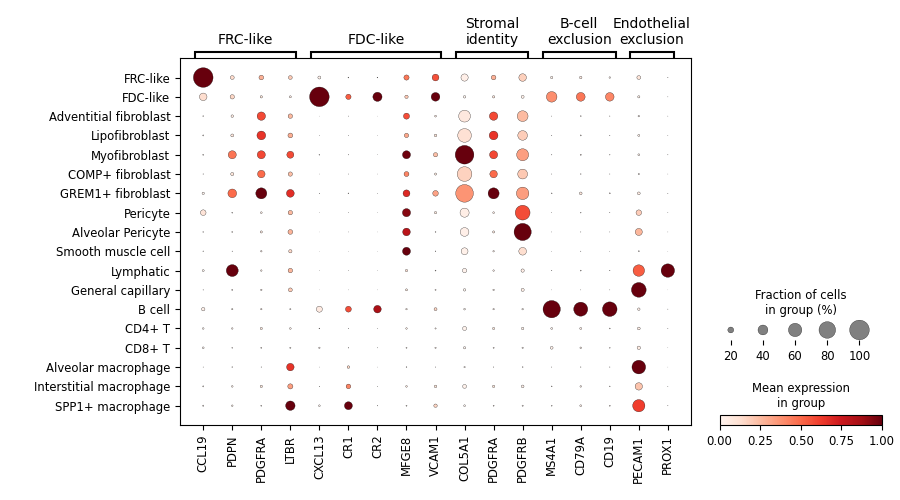

In [9]:
# Dotplot
fig, ax = plt.subplots(figsize=(9,5))
fig.subplots_adjust(top=1, left=0.2, right=0.98, bottom=0.15)
sc.pl.dotplot(
    adata_sub,
    var_names=sig_genes,
    groupby="subtype",
    categories_order=cell_order,
    standard_scale="var",
    expression_cutoff=0,
    mean_only_expressed=False,
    use_raw=False,
    cmap="Reds",
    var_group_rotation=0,
    ax=ax
)

ax.tick_params("both", labelsize=12)

fig.get_children()[5].set_title("Fraction expressed (%)", fontsize=10)
fig.get_children()[6].set_title("Mean expression\n(gene-scaled)", fontsize=10)
fig.savefig(f"{WORK_PATH}Figure/013_FRCFDC.png", dpi=300, format="png", bbox_inches=None)